### Vanishing Gradient

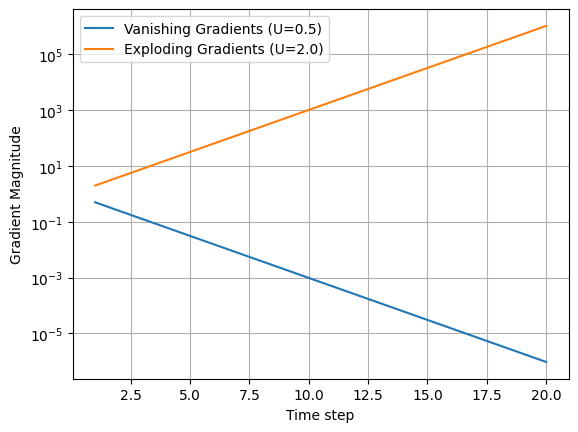

In [5]:
import numpy as np
import matplotlib.pyplot as plt

T = 20

Us = [0.5, 2.0]
labels = ["Vanishing Gradients", "Exploding Gradients"]

for U, label in zip(Us, labels):
  grads = []
  grad = 1.0

  for t in range(T):
    grad *= U
    grads.append(grad)

  plt.plot(range(1, T+1), grads, label=f"{label} (U={U})")

plt.xlabel("Time step")
plt.ylabel("Gradient Magnitude")
plt.yscale('log')
plt.legend()
plt.grid()
plt.show()


# LSTM -Long Short Term Memory

In [10]:
import numpy as np

# sigmoid and tanh
def sigmoid(x):
  return 1/(1+np.exp(-x))

def tanh(x):
  return np.tanh(x)

# input and previous states
x_t = 1.0
h_prev = 0.5
c_prev = 0.3

# weights and biases(simplified)
W_f = W_i = W_o = W_c =  1.0
b_f = b_i = b_o =b_c=0.0

# Concatenate
concat = h_prev + x_t

# 1.  Forget gate
f_t = sigmoid(W_f * concat + b_f)
print(f"Forget gate: {f_t:.4f}")

# 2. Input gate
i_t = sigmoid(W_i * concat + b_i)
print(f"Input gate:  {i_t:.4f}")

# 3. Candidate Cell state
c_hat_t = tanh(W_c * concat + b_c)
print(f"Candidate cell state:  {c_hat_t:.4f}")

# 4. New cell state
c_t = f_t * c_prev + i_t * c_hat_t
print(f"New cell state:  {c_t:.4f}")

# 5. Output Gate
o_t = sigmoid(W_o * concat + b_o)
print(f"Output gate: {o_t:.4f}")

# 6. New hidden state
h_t = o_t * tanh(c_t)
print(f"New hidden state:  {h_t:.4f}")

Forget gate: 0.8176
Input gate:  0.8176
Candidate cell state:  0.9051
New cell state:  0.9853
Output gate: 0.8176
New hidden state:  0.6176


## Custom LSTM


In [14]:
import numpy as np

def sigmoid(x):
  return 1/(1+np.exp(-x))

def tanh(x):
  return np.tanh(x)

class MiniLSTM:
  def __init__(self):
    # weights and biases for 1-unit LSTM
    self.W_f = np.array([[1.0, 1.0]])
    self.W_i = np.array([[1.0, 1.0]])
    self.W_c = np.array([[1.0, 1.0]])
    self.W_o = np.array([[1.0, 1.0]])

    self.b_f = np.array([[0.0]])
    self.b_i = np.array([[0.0]])
    self.b_c = np.array([[0.0]])
    self.b_o = np.array([[0.0]])

  def step(self, x_t, h_prev, c_prev):
    x_t = np.array([[x_t]]) if np.isscalar(x_t) else x_t
    h_prev = np.array([[h_prev]]) if np.isscalar(h_prev) else h_prev

    concat = np.concatenate((h_prev, x_t))

    # 1. Gates
    f_t = sigmoid(self.W_f @ concat + self.b_f)
    i_t = sigmoid(self.W_i @ concat + self.b_i)
    c_hat_t = tanh(self.W_c @ concat + self.b_c)
    c_t = f_t * c_prev + i_t * c_hat_t
    o_t = sigmoid(self.W_o @ concat + self.b_o)
    h_t = o_t * tanh(c_t)

    return h_t, c_t

# initialize the model
model = MiniLSTM()
h, c = 0.0, 0.0

sequence= [0.1, 0.2, 0.3]

for idx, x in enumerate(sequence):
  h, c = model.step(x, h, c)
  print(f"Step {idx+1}: x={x:.4f}, h={h.item():.4f}, c={c.item():.4f}")

Step 1: x=0.1000, h=0.0274, c=0.0523
Step 2: x=0.2000, h=0.0848, c=0.1536
Step 3: x=0.3000, h=0.1786, c=0.3097


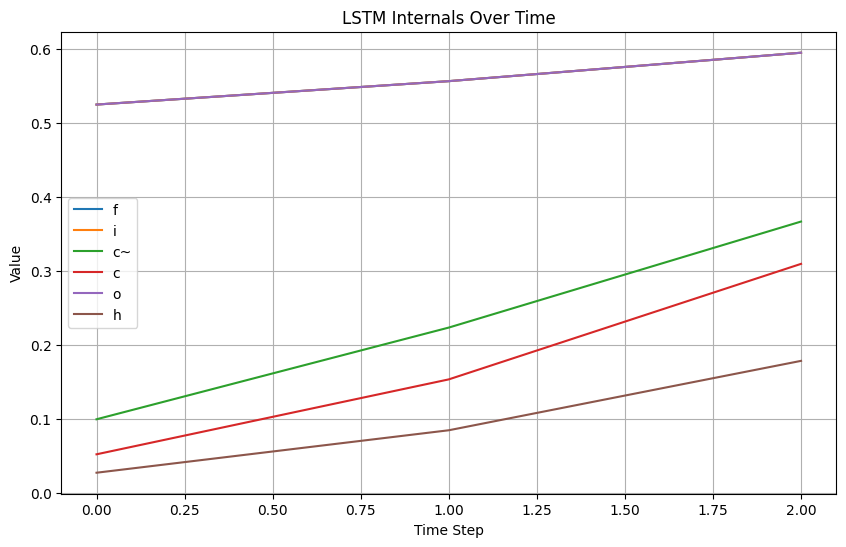

In [16]:
import numpy as np

def sigmoid(x):
  return 1/(1+np.exp(-x))

def tanh(x):
  return np.tanh(x)

class MiniLSTM:
  def __init__(self):
    # weights and biases for 1-unit LSTM
    self.W_f = np.array([[1.0, 1.0]])
    self.W_i = np.array([[1.0, 1.0]])
    self.W_c = np.array([[1.0, 1.0]])
    self.W_o = np.array([[1.0, 1.0]])

    self.b_f = np.array([[0.0]])
    self.b_i = np.array([[0.0]])
    self.b_c = np.array([[0.0]])
    self.b_o = np.array([[0.0]])

  def step(self, x_t, h_prev, c_prev):
    x_t = np.array([[x_t]]) if np.isscalar(x_t) else x_t
    h_prev = np.array([[h_prev]]) if np.isscalar(h_prev) else h_prev

    concat = np.concatenate((h_prev, x_t))

    # 1. Gates
    f_t = sigmoid(self.W_f @ concat + self.b_f)
    i_t = sigmoid(self.W_i @ concat + self.b_i)
    c_hat_t = tanh(self.W_c @ concat + self.b_c)
    c_t = f_t * c_prev + i_t * c_hat_t
    o_t = sigmoid(self.W_o @ concat + self.b_o)
    h_t = o_t * tanh(c_t)

    return h_t, c_t

class DebugLSTM(MiniLSTM):
    def __init__(self):
        super().__init__()
        self.history = {'f':[], 'i':[], 'c~':[], 'c':[], 'o':[], 'h':[]}

    def step(self, x_t, h_prev, c_prev):
      x_t = np.array([[x_t]]) if np.isscalar(x_t) else x_t
      h_prev = np.array([[h_prev]]) if np.isscalar(h_prev) else h_prev

      concat = np.concatenate((h_prev, x_t))

      # 1. Gates
      f_t = sigmoid(self.W_f @ concat + self.b_f)
      i_t = sigmoid(self.W_i @ concat + self.b_i)
      c_hat_t = tanh(self.W_c @ concat + self.b_c)
      c_t = f_t * c_prev + i_t * c_hat_t
      o_t = sigmoid(self.W_o @ concat + self.b_o)
      h_t = o_t * tanh(c_t)

      # Store Values for plotting
      self.history['f'].append(f_t.item())
      self.history['i'].append(i_t.item())
      self.history['c~'].append(c_hat_t.item())
      self.history['c'].append(c_t.item())
      self.history['o'].append(o_t.item())
      self.history['h'].append(h_t.item())

      return h_t, c_t


# Run
model  = DebugLSTM()
h, c = 0.0, 0.0

sequence= [0.1, 0.2, 0.3]

for idx, x in enumerate(sequence):
  h, c = model.step(x, h, c)


# ploting

plt.figure(figsize = (10,6))
for key in model.history:
  plt.plot(model.history[key], label = key)

plt.legend()
plt.title("LSTM Internals Over Time")
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.grid(True)
plt.show()

In [17]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

word_index = imdb.get_word_index()
word_index = {k: (v+3) for k, v in word_index.items()}
word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2
word_index["<UNUSED>"] = 3

index_word = {v:k for k, v in word_index.items()}

def encode_text(text):
  tokens = text.lower().split()
  encoded = [1]

  for word in tokens:
    idx = word_index.get(word, 2)
    encoded.append(idx)


  return pad_sequences([encoded], maxlen=200)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step


In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=5000)

x_train = pad_sequences(x_train, maxlen=200)
x_test = pad_sequences(x_test, maxlen=200)

model = Sequential()
model.add(Embedding(5000, 32, input_length=200))
model.add(LSTM(64))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss = 'binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=10, batch_size=64)


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.7656 - loss: 0.4719 - val_accuracy: 0.8622 - val_loss: 0.3275
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8846 - loss: 0.2865 - val_accuracy: 0.8744 - val_loss: 0.3055
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8997 - loss: 0.2470 - val_accuracy: 0.8742 - val_loss: 0.3040
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9178 - loss: 0.2075 - val_accuracy: 0.8609 - val_loss: 0.3756
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9309 - loss: 0.1788 - val_accuracy: 0.8613 - val_loss: 0.3511
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9419 - loss: 0.1529 - val_accuracy: 0.8609 - val_loss: 0.4046
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9475 - loss: 0.1413 - val_accuracy: 0.8648 - val_loss: 0.3950
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.9576 - loss: 0.1158 - val_acc

In [19]:
# Sample text

sample_review = "this move was absolutely fantanstic and i loved every moment"

encoded_review = encode_text(sample_review)
prediction = model.predict(encoded_review)

print(f"Prediction: {prediction[0][0]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step
Prediction: 0.5156354904174805
